# 1. Comparer les méthodes numériques

Le problème à trois corps n'a pas de solution générale en formule fermée : il faut l'intégrer numériquement.
Ce notebook compare trois schémas à pas fixe codés à la main dans `threebody/integrators.py` :

| Méthode | Ordre | Évaluations de la force par pas | Symplectique |
|---|---|---|---|
| Euler explicite | 1 | 1 | non |
| Runge-Kutta 4 (RK4) | 4 | 4 | non |
| Velocity Verlet | 2 | 1 | oui |

La référence est DOP853 (SciPy), un Runge-Kutta d'ordre 8 à pas adaptatif.

**Le banc d'essai** est l'orbite en huit (Chenciner & Montgomery, 2000) : trois masses égales qui se poursuivent
sur une même courbe. Elle est périodique, donc on sait exactement où les corps doivent être après une période.

In [1]:
import numpy as np

from threebody import figure_eight, integrate, integrate_adaptive
from threebody.analysis import convergence_study, energy_comparison, observed_order
from threebody.physics import angular_momentum, momentum, relative_energy_error, total_energy
from threebody.plots import plot_convergence, plot_energy_error
from threebody.scenarios import FIGURE_EIGHT_PERIOD

ic = figure_eight()
print("total energy    :", total_energy(ic.r, ic.v, ic.m))
print("total momentum  :", momentum(ic.v, ic.m))
print("angular momentum:", angular_momentum(ic.r, ic.v, ic.m))

total energy    : -1.2871419917663258
total momentum  : [0. 0. 0.]
angular momentum: [0. 0. 0.]


## Les équations

Pour chaque corps $i$ (avec $G = 1$) :

$$\ddot{\mathbf r}_i = \sum_{j \neq i} m_j \, \frac{\mathbf r_j - \mathbf r_i}{\lVert \mathbf r_j - \mathbf r_i \rVert^3}$$

La dynamique exacte conserve l'énergie $E = K + U$, la quantité de mouvement $\mathbf P$ et le moment cinétique $\mathbf L$.
Une simulation ne les conserve qu'approximativement : **l'erreur sur l'énergie mesure donc la qualité de l'intégrateur**.

## Expérience 1 : conservation de l'énergie

Même problème, même pas de temps `dt = 0.01`, sur 30 périodes.

euler    largest relative energy error = 1.49e+01
rk4      largest relative energy error = 7.88e-08
verlet   largest relative energy error = 5.90e-05
dop853   largest relative energy error = 1.23e-08


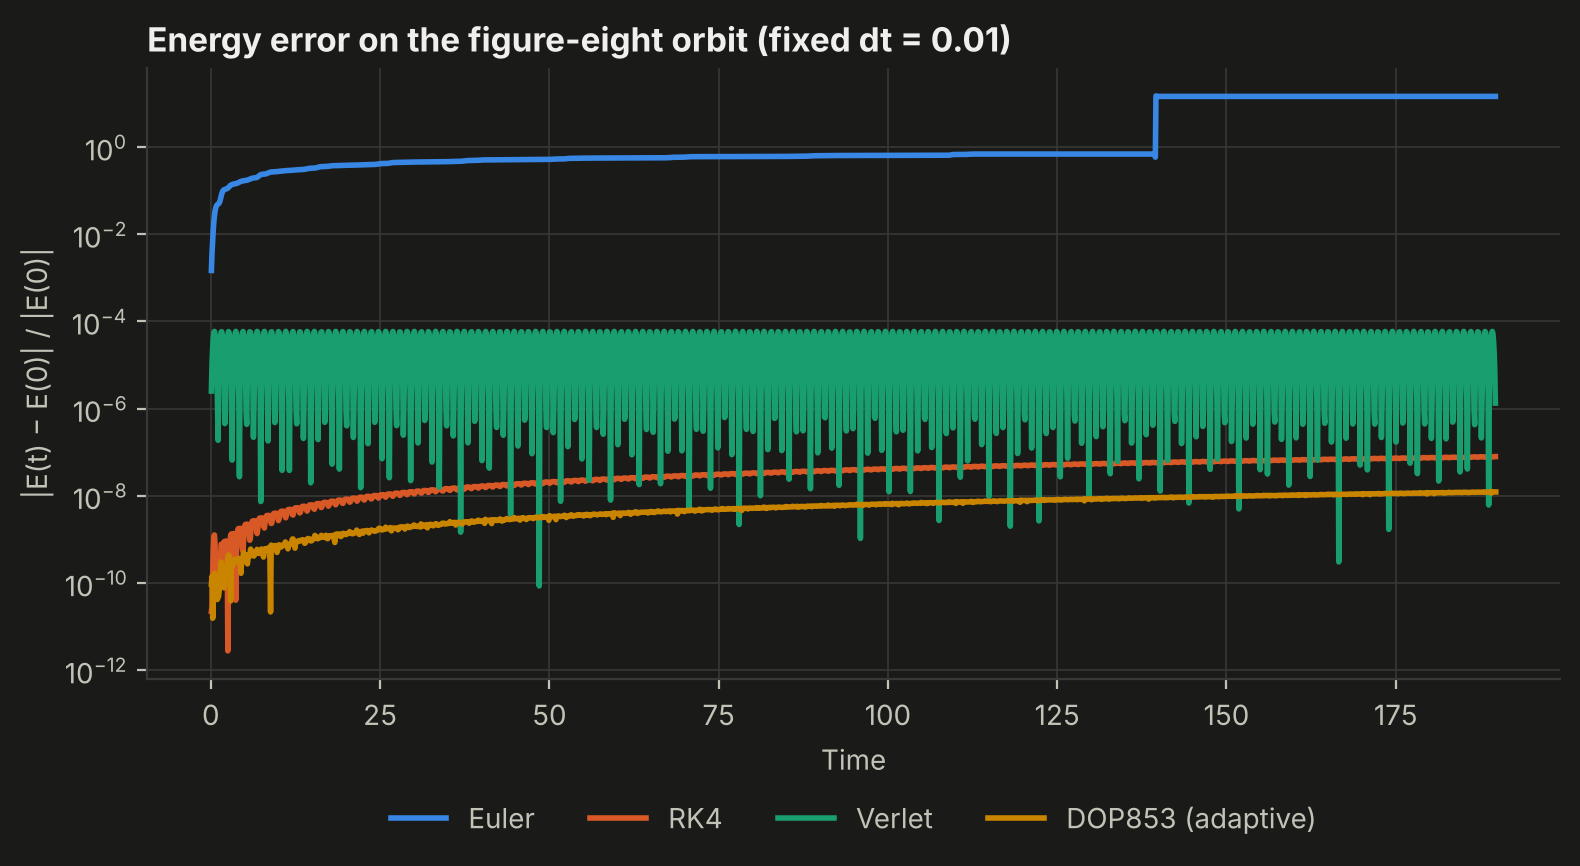

In [2]:
t_end, dt = 30 * FIGURE_EIGHT_PERIOD, 0.01
trajs = energy_comparison(ic, t_end, dt)

for name, traj in trajs.items():
    print(f"{name:8s} largest relative energy error = {relative_energy_error(traj).max():.2e}")

fig = plot_energy_error(trajs, title=f"Energy error on the figure-eight orbit (fixed dt = {dt})")

**Lecture du graphique**

- **Euler** : l'énergie dérive dès le début. L'erreur dépasse 100 %, l'orbite en huit est détruite
  (le saut correspond à une rencontre proche entre deux corps, que le schéma gère très mal).
- **RK4** : très précis, mais l'erreur grandit lentement et régulièrement. Sur un temps très long, elle finit par compter.
- **Verlet** : moins précis à chaque pas (ordre 2), mais l'erreur **oscille sans grandir**.
  C'est la signature d'un schéma symplectique : il conserve exactement une énergie « voisine » de la vraie.
  C'est pour cela qu'on l'utilise en mécanique céleste et en dynamique moléculaire.
- **DOP853** : la référence, avec un pas qui s'adapte tout seul.

## Expérience 2 : ordre de convergence

Pour une méthode d'ordre $p$, l'erreur se comporte comme $C \, dt^p$.
En échelle log-log, on doit donc voir une droite de pente $p$.

euler    observed order = 0.97
rk4      observed order = 4.11
verlet   observed order = 2.00


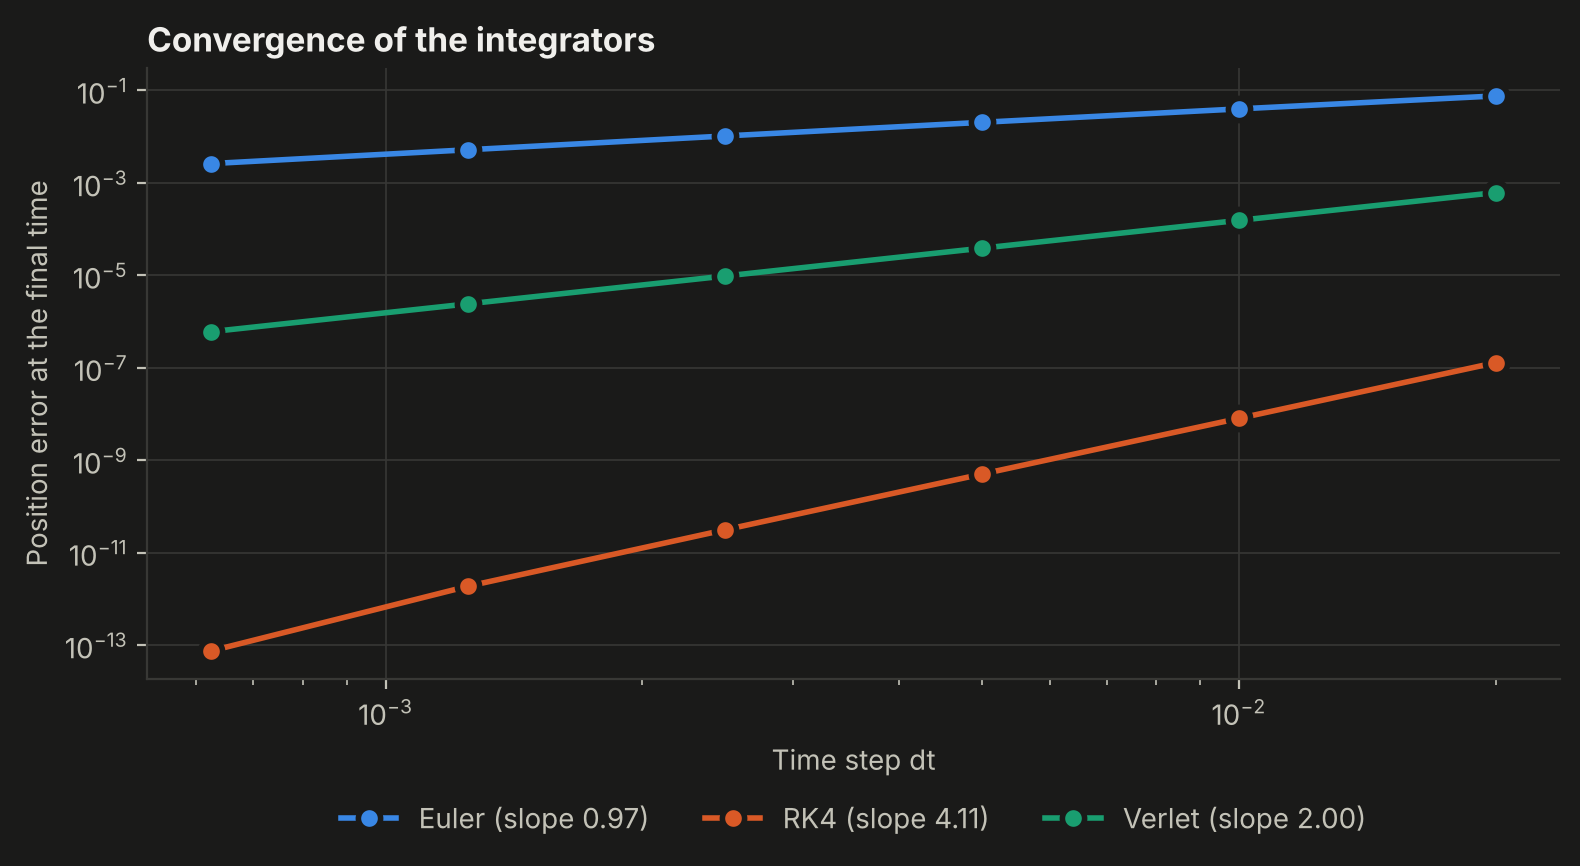

In [3]:
dts = 0.02 / 2 ** np.arange(6)
errors = convergence_study(ic, t_end=1.0, dts=dts)

for name, err in errors.items():
    print(f"{name:8s} observed order = {observed_order(dts, err):.2f}")

fig = plot_convergence(dts, errors)

Les pentes mesurées retrouvent les ordres théoriques : 1 pour Euler, 2 pour Verlet, 4 pour RK4.
Diviser le pas par 2 divise l'erreur par 2 (Euler), 4 (Verlet) ou 16 (RK4).

## Expérience 3 : la périodicité de l'orbite en huit

Après une période exacte, les trois corps doivent revenir à leur point de départ.

In [4]:
for method, dt in [("euler", 1e-3), ("verlet", 1e-3), ("rk4", 1e-3)]:
    n_steps = round(FIGURE_EIGHT_PERIOD / dt)
    traj = integrate(ic, FIGURE_EIGHT_PERIOD, FIGURE_EIGHT_PERIOD / n_steps, method=method)
    print(f"{method:8s} distance to the start after one period: {np.abs(traj.r[-1] - ic.r).max():.1e}")

ref = integrate_adaptive(ic, FIGURE_EIGHT_PERIOD, n_out=2, rtol=1e-12, atol=1e-13)
print(f"{'dop853':8s} distance to the start after one period: {np.abs(ref.r[-1] - ic.r).max():.1e}")

euler    distance to the start after one period: 1.3e-01
verlet   distance to the start after one period: 1.6e-06


rk4      distance to the start after one period: 3.0e-08
dop853   distance to the start after one period: 3.0e-08


## À retenir

- L'ordre d'une méthode dit comment l'erreur diminue quand on réduit le pas, pas comment elle évolue sur le long terme.
- Un schéma symplectique (Verlet) est moins précis à court terme mais ne dérive pas.
- Pour des trajectoires chaotiques avec des rencontres proches, un pas adaptatif (DOP853) est indispensable :
  c'est lui qui sert pour les animations et l'étude du chaos (notebook 2).